# Discussion

This notebook computes the values used in the discussion of the results: the energy consumed by the study, the idle consumption of the server, the checks of robustness of the main results, and the differences between the subjects of the benchmark.

The process consists of:
1. **Energy and Run Time of the Study**: Adding up the energy and the time of every run that was executed.
2. **Energy in Practical Terms**: Converting the energy of the study into everyday quantities.
3. **Idle Consumption**: Comparing the power of the GPU during inference with its power when idle.
4. **Robustness**: Repeating the main results with the strict accuracy and with the energy above the idle consumption.
5. **Subjects**: Comparing the energy, the response length and the accuracy of the subjects of the benchmark.
6. **Chance Level**: Repeating the ranking and the yearly changes with the accuracy above the chance level.
7. **Time per Question**: Comparing the time and the energy of a question over the model runs.
8. **Size of the Selected Models**: Relating the size of the instruct runs to their release date, and listing the smaller models that were not selected.
9. **Key Values**: Printing the main values of this notebook.

### Setup & Imports
We load the tables built by `00-dataset.ipynb`, the run tables of the executions and the chart helpers of `common.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from common import (
    CATEGORY_COLORS,
    CATEGORY_ORDER,
    FAMILY_ORDER,
    IDLE_DIR,
    MODE_COLORS,
    QUESTIONS,
    RESULTS_DIRS,
    legend_handles,
    load_model_runs,
    load_questions,
    load_run_table,
    pareto_front,
    plain_log_axis,
    save_chart,
    scatter_model_runs,
    short_name,
)

all_runs = load_model_runs(include_superseded=True)
model_runs = all_runs[all_runs["in_study"]].sort_values(["release_date", "model_run"]).reset_index(drop=True)
questions = load_questions(model_runs)
FAMILIES = [family for family in FAMILY_ORDER if family in set(model_runs["family"])]

JOULES_PER_KWH = 3.6e6
print(f"Model runs of the study: {len(model_runs)}   runs kept for comparison only: {len(all_runs) - len(model_runs)}")

Model runs of the study: 53   runs kept for comparison only: 3


### 1. Energy and Run Time of the Study
We add up the energy and the time of every run that was executed, in the main execution and in the supplementary one. Energy was only measured during the inferences, so the time is given twice: the time of the inferences, and the whole time of the runs, which also includes loading the model, preparing the prompts and warming up the hardware. The CPU and memory energy of the main execution covers one of the two processors, and that of the supplementary execution covers both.

In [2]:
rows = []
for execution in RESULTS_DIRS:
    run_table = load_run_table(execution)
    rows.append({
        "Execution": execution,
        "Runs": len(run_table),
        "Inferences": len(run_table) * QUESTIONS,
        "GPU energy (kWh)": run_table["total_inference_gpu_joules"].sum() / JOULES_PER_KWH,
        "CPU energy (kWh)": run_table["total_inference_cpu_joules"].sum() / JOULES_PER_KWH,
        "Memory energy (kWh)": run_table["total_inference_dram_joules"].sum() / JOULES_PER_KWH,
        "Measured energy (kWh)": run_table["total_inference_joules"].sum() / JOULES_PER_KWH,
        "Inference time (hours)": run_table["total_inference_time_seconds"].sum() / 3600,
        "Run time (hours)": run_table["runtime_seconds"].sum() / 3600,
    })
executions = pd.DataFrame(rows).set_index("Execution")
executions.loc["Both"] = executions.sum()
executions["Run time (days)"] = executions["Run time (hours)"] / 24
executions["GPU share of the measured energy (%)"] = 100 * executions["GPU energy (kWh)"] / executions["Measured energy (kWh)"]
executions["Time with energy measured (%)"] = 100 * executions["Inference time (hours)"] / executions["Run time (hours)"]

both = executions.loc["Both"]
print(f"Total run time of the experiment: {both['Run time (hours)']:,.1f} hours ({both['Run time (days)']:.1f} days), of which {executions.loc['main', 'Run time (hours)']:,.1f} hours in the main execution and {executions.loc['mistral-bf16', 'Run time (hours)']:.1f} hours in the supplementary one")
print(f"Time of the inferences, in which the energy was measured: {both['Inference time (hours)']:,.1f} hours ({both['Time with energy measured (%)']:.1f}% of the run time)")
executions.round(1).T

Total run time of the experiment: 1,209.5 hours (50.4 days), of which 1,188.9 hours in the main execution and 20.6 hours in the supplementary one
Time of the inferences, in which the energy was measured: 1,151.1 hours (95.2% of the run time)


Execution,main,mistral-bf16,Both
Runs,530.0,18.0,548.0
Inferences,197160.0,6696.0,203856.0
GPU energy (kWh),336.9,5.9,342.8
CPU energy (kWh),98.9,3.6,102.6
Memory energy (kWh),13.5,0.5,14.0
Measured energy (kWh),449.4,10.0,459.4
Inference time (hours),1131.5,19.6,1151.1
Run time (hours),1188.9,20.6,1209.5
Run time (days),49.5,0.9,50.4
GPU share of the measured energy (%),75.0,59.0,74.6


We split the GPU energy of the main execution by size category and operating mode.

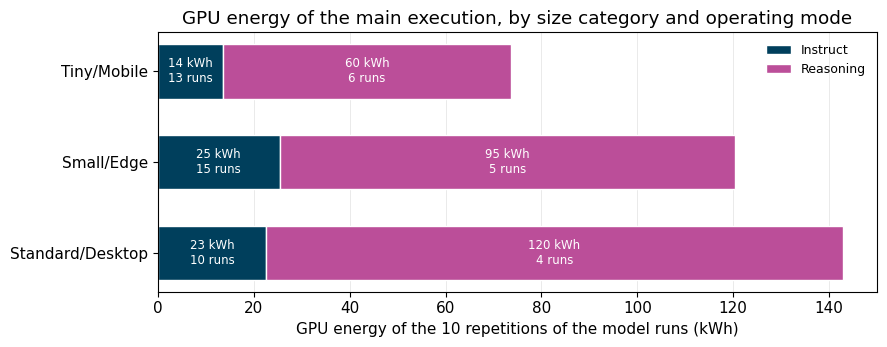

           model_runs  gpu_kwh  share (%)
mode                                     
Instruct           38     61.7       18.3
Reasoning          15    275.2       81.7

The five model runs with the most GPU energy hold 44% of it: Ministral-3-14B-Reasoning-2512, Phi-4-reasoning, Qwen3.5-9B (R), DeepSeek-R1-Distill-Qwen-14B, Qwen3-14B (R)


In [3]:
main = all_runs[all_runs["execution"] == "main"].assign(gpu_kwh=lambda runs: runs["total_gpu_joules"] / JOULES_PER_KWH)
by_group = main.pivot_table(index="category", columns="mode", values="gpu_kwh", aggfunc="sum").reindex(CATEGORY_ORDER)
group_runs = main.pivot_table(index="category", columns="mode", values="model_run", aggfunc="count").reindex(CATEGORY_ORDER)

fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(by_group))
for mode, color in MODE_COLORS.items():
    bars = ax.barh(by_group.index, by_group[mode], left=left, color=color, edgecolor="w", linewidth=1, height=0.6, label=mode)
    for bar, value, runs in zip(bars, by_group[mode], group_runs[mode]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2, f"{value:.0f} kWh\n{runs} runs", ha="center", va="center", fontsize=8.5, color="w")
    left += by_group[mode].to_numpy()
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("GPU energy of the 10 repetitions of the model runs (kWh)")
ax.set_title("GPU energy of the main execution, by size category and operating mode")
ax.legend(loc="upper right", fontsize=9, frameon=False)
plt.tight_layout()
save_chart(fig, "discussion-energy-of-the-study")
plt.show()

by_mode = main.groupby("mode").agg(model_runs=("model_run", "size"), gpu_kwh=("gpu_kwh", "sum"))
by_mode["share (%)"] = 100 * by_mode["gpu_kwh"] / by_mode["gpu_kwh"].sum()
top = main.nlargest(5, "gpu_kwh")
print(by_mode.round(1).to_string())
print(f"\nThe five model runs with the most GPU energy hold {100 * top['gpu_kwh'].sum() / main['gpu_kwh'].sum():.0f}% of it: {', '.join(top['model_run'].map(short_name))}")

### 2. Energy in Practical Terms
We convert the GPU energy of a question and the energy of the study into everyday quantities. Three references are used: the electricity that one person uses at home in the European Union (1,545 kWh per year in 2023, Eurostat), the average consumption of an electric car in real-world conditions (189 Wh per km, EV Database), and the energy of charging a smartphone (0.019 kWh, United States Environmental Protection Agency).

In [4]:
# Electricity consumption per capita in the household sector of the EU in 2023 (Eurostat, Electricity and heat statistics)
HOUSEHOLD_KWH_PER_PERSON_YEAR = 1545
# Average energy consumption of the electric cars on sale, in real-world conditions (EV Database, energy consumption cheatsheet)
ELECTRIC_CAR_KWH_PER_KM = 0.189
# Energy of charging a smartphone (EPA, Greenhouse Gas Equivalencies Calculator, calculations and references)
SMARTPHONE_CHARGE_KWH = 0.019

rows = []
for name, energy in {
    "GPU energy of both executions": executions.loc["Both", "GPU energy (kWh)"],
    "Measured energy of both executions": executions.loc["Both", "Measured energy (kWh)"],
}.items():
    rows.append({
        "Quantity": name,
        "kWh": round(energy, 1),
        "Days of household electricity of one person in the EU": round(365 * energy / HOUSEHOLD_KWH_PER_PERSON_YEAR),
        "Distance in an electric car (km)": round(energy / ELECTRIC_CAR_KWH_PER_KM, -1),
        "Smartphone charges": round(energy / SMARTPHONE_CHARGE_KWH, -2),
    })
equivalents = pd.DataFrame(rows).set_index("Quantity")

# GPU energy of one question in watt-hours, the distance that an electric car covers with it,
# and the number of questions that use the energy of one smartphone charge
per_question = model_runs.assign(wh_per_question=model_runs["gpu_joules_per_question"] / 3600).groupby("mode")["wh_per_question"].agg(["min", "median", "max"])
per_question["metres in an electric car (median)"] = per_question["median"] / ELECTRIC_CAR_KWH_PER_KM
per_question["questions per smartphone charge (median)"] = 1000 * SMARTPHONE_CHARGE_KWH / per_question["median"]
print("GPU energy per question (Wh):")
print(per_question.round(2).to_string())
equivalents

GPU energy per question (Wh):
            min  median   max  metres in an electric car (median)  questions per smartphone charge (median)
mode                                                                                                       
Instruct   0.05    0.39   1.3                                2.08                                     48.26
Reasoning  1.10    4.99  10.9                               26.42                                      3.81


,kWh,Days of household electricity of one person in the EU,Distance in an electric car (km),Smartphone charges
Quantity,,,,
GPU energy of both executions,342.8,81,1810.0,18000.0
Measured energy of both executions,459.4,109,2430.0,24200.0


### 3. Idle Consumption
We read the measurements of the idle server (10 repetitions of 30 seconds, with no model loaded), and compare the idle power of the GPU with its average power during the inferences of each model run. For each model run, we compute the share of its GPU energy that the idle GPU would have used in the same time.

Idle power: GPU 34.6 W, both processors 122.1 W, their memory 23.8 W, total 180.4 W
First processor alone: 62.1 W, and its memory 11.9 W


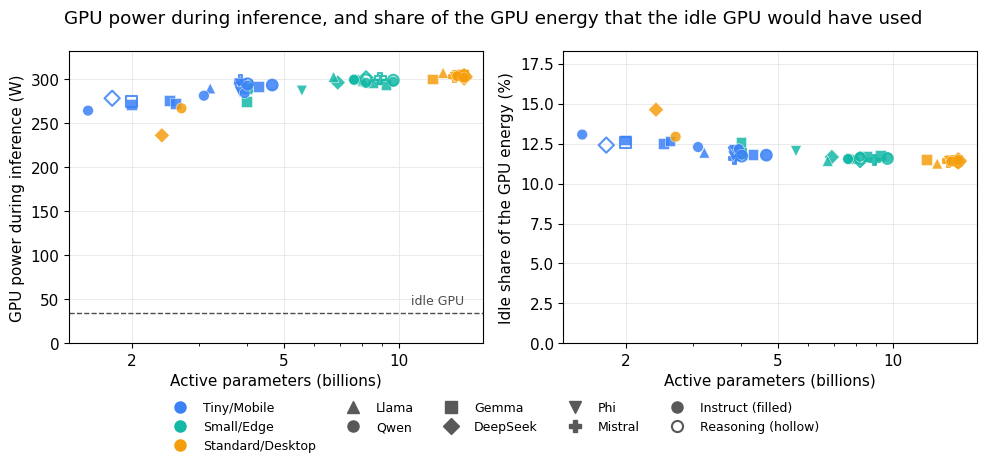

Average GPU power during inference: 236 W to 307 W (6.8 to 8.9 times the idle power)
Share of the GPU energy that the idle GPU would have used: 11.3% to 14.6% (median 11.7%)


In [5]:
idle = pd.read_csv(IDLE_DIR / "run_table.csv").median(numeric_only=True)
IDLE_GPU_WATTS = idle["avg_gpu_power_watts"]
print(f"Idle power: GPU {IDLE_GPU_WATTS:.1f} W, both processors {idle['avg_cpu_power_watts']:.1f} W, their memory {idle['avg_dram_power_watts']:.1f} W, total {IDLE_GPU_WATTS + idle['avg_cpu_power_watts'] + idle['avg_dram_power_watts']:.1f} W")
print(f"First processor alone: {idle['avg_cpu_0_power_watts']:.1f} W, and its memory {idle['avg_dram_0_power_watts']:.1f} W")

model_runs["idle_share"] = 100 * IDLE_GPU_WATTS * model_runs["total_inference_seconds"] / model_runs["total_gpu_joules"]
model_runs["joules_above_idle_per_question"] = model_runs["gpu_joules_per_question"] * (1 - model_runs["idle_share"] / 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True)
scatter_model_runs(axes[0], model_runs, "activated_parameters", "gpu_power_watts")
axes[0].axhline(IDLE_GPU_WATTS, color="0.3", linewidth=1, linestyle="--")
axes[0].text(model_runs["activated_parameters"].max(), IDLE_GPU_WATTS + 6, "idle GPU", ha="right", va="bottom", fontsize=9, color="0.3")
axes[0].set_ylim(0, 1.08 * model_runs["gpu_power_watts"].max())
axes[0].set_ylabel("GPU power during inference (W)")
scatter_model_runs(axes[1], model_runs, "activated_parameters", "idle_share")
axes[1].set_ylim(0, 1.25 * model_runs["idle_share"].max())
axes[1].set_ylabel("Idle share of the GPU energy (%)")
for ax in axes:
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis)
    ax.set_xlabel("Active parameters (billions)")
fig.legend(handles=legend_handles(families=FAMILIES), loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle("GPU power during inference, and share of the GPU energy that the idle GPU would have used")
plt.tight_layout(rect=(0, 0.12, 1, 1))
save_chart(fig, "discussion-idle-consumption")
plt.show()

print(f"Average GPU power during inference: {model_runs['gpu_power_watts'].min():.0f} W to {model_runs['gpu_power_watts'].max():.0f} W ({model_runs['gpu_power_watts'].min() / IDLE_GPU_WATTS:.1f} to {model_runs['gpu_power_watts'].max() / IDLE_GPU_WATTS:.1f} times the idle power)")
print(f"Share of the GPU energy that the idle GPU would have used: {model_runs['idle_share'].min():.1f}% to {model_runs['idle_share'].max():.1f}% (median {model_runs['idle_share'].median():.1f}%)")

### 4. Robustness
We repeat the main results with two changes: the strict accuracy, in which every response that reached the output limit counts as wrong, and the GPU energy above the idle consumption. For each version, the table gives the rank correlation with the ranking by correct answers per kJ, the largest change of position, the model runs on the Pareto front, and the yearly change of the correct answers per kJ of the instruct runs of each size category.

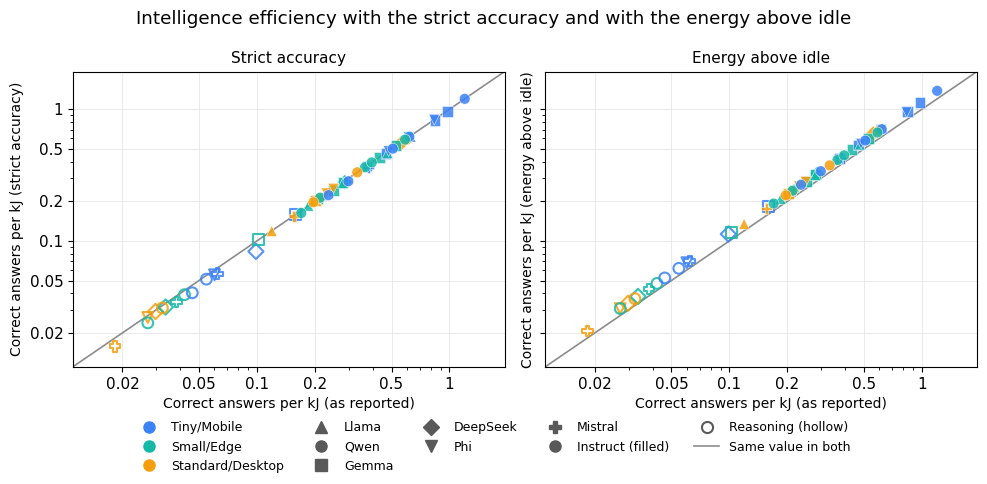

Version,As reported,Strict accuracy,Energy above idle,Strict accuracy and energy above idle
Rank correlation,1.000,0.999,1.000,0.999
Largest change of position,0.000,2.000,1.000,2.000
Runs on the Pareto front,9.000,8.000,9.000,8.000
Reasoning runs on the front,0.000,0.000,0.000,0.000
Runs on the front in both,9.000,7.000,9.000,7.000
"Yearly change, Tiny/Mobile",0.622,0.612,0.621,0.611
"Yearly change, Small/Edge",0.931,0.923,0.933,0.925
"Yearly change, Standard/Desktop",0.962,0.963,0.958,0.960


In [6]:
VERSIONS = {
    "As reported": ("accuracy", "gpu_joules_per_question"),
    "Strict accuracy": ("strict_accuracy", "gpu_joules_per_question"),
    "Energy above idle": ("accuracy", "joules_above_idle_per_question"),
    "Strict accuracy and energy above idle": ("strict_accuracy", "joules_above_idle_per_question"),
}
years = (model_runs["release_date"] - pd.Timestamp("2023-01-01")).dt.days / 365.25
reported_front = set(pareto_front(model_runs, "gpu_joules_per_question", "accuracy")["model_run"])

rows, efficiency = [], {}
for name, (accuracy, energy) in VERSIONS.items():
    efficiency[name] = 1000 * model_runs[accuracy] / model_runs[energy]
    position_change = (efficiency["As reported"].rank(ascending=False) - efficiency[name].rank(ascending=False)).abs()
    front = set(pareto_front(model_runs, energy, accuracy)["model_run"])
    row = {
        "Version": name,
        "Rank correlation": efficiency["As reported"].corr(efficiency[name], method="spearman"),
        "Largest change of position": int(position_change.max()),
        "Runs on the Pareto front": len(front),
        "Reasoning runs on the front": int(model_runs.loc[model_runs["model_run"].isin(front), "mode"].eq("Reasoning").sum()),
        "Runs on the front in both": len(front & reported_front),
    }
    for category in CATEGORY_ORDER:
        group = (model_runs["category"] == category) & (model_runs["mode"] == "Instruct")
        row[f"Yearly change, {category}"] = np.exp(np.polyfit(years[group], np.log(efficiency[name][group]), 1)[0])
    rows.append(row)
robustness = pd.DataFrame(rows).set_index("Version")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
limits = [0.7 * min(values.min() for values in efficiency.values()), 1.4 * max(values.max() for values in efficiency.values())]
for ax, name in zip(axes, ["Strict accuracy", "Energy above idle"]):
    ax.plot(limits, limits, color="0.55", linewidth=1.2, zorder=1)
    scatter_model_runs(ax, model_runs.assign(reported=efficiency["As reported"], version=efficiency[name]), "reported", "version")
    ax.set_xscale("log")
    ax.set_yscale("log")
    plain_log_axis(ax.xaxis)
    plain_log_axis(ax.yaxis)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel("Correct answers per kJ (as reported)", fontsize=10)
    ax.set_ylabel(f"Correct answers per kJ ({name.lower()})", fontsize=10)
    ax.set_title(name, fontsize=11)
handles = legend_handles(families=FAMILIES) + [Line2D([], [], color="0.55", linewidth=1.2, label="Same value in both")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle("Intelligence efficiency with the strict accuracy and with the energy above idle")
plt.tight_layout(rect=(0, 0.11, 1, 1))
save_chart(fig, "discussion-robustness")
plt.show()

robustness.round(3).T

### 5. Subjects
We compare the 14 subjects of the benchmark. For each model run, the GPU energy and the generated tokens of the questions of a subject are divided by those of all its questions, so that model runs of very different sizes can be compared. The figure shows this relative energy for every model run, grouped by operating mode and size category, with the subjects ordered from the most to the least demanding. The table gives the median over the model runs, the accuracy of each mode and the share of the responses of the reasoning runs that reached the output limit.

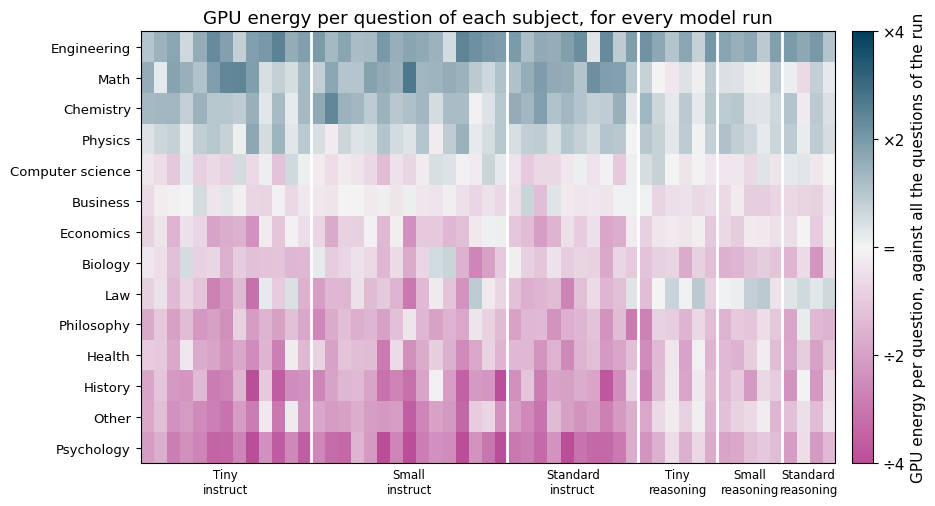

,questions,relative_energy,relative_tokens,accuracy_instruct,accuracy_reasoning,reasoning_at_limit
subject,,,,,,
engineering,30,1.81,1.79,0.387,0.585,49.2
math,42,1.45,1.44,0.497,0.789,21.6
chemistry,35,1.41,1.40,0.470,0.732,23.9
physics,40,1.26,1.26,0.472,0.722,26.1
computer science,13,0.90,0.90,0.561,0.770,14.4
business,24,0.89,0.90,0.562,0.817,12.8
economics,26,0.76,0.77,0.461,0.685,9.3
biology,22,0.73,0.73,0.630,0.822,5.2
law,34,0.72,0.72,0.285,0.391,14.3


In [7]:
by_subject = questions.groupby(["model_run", "subject"]).agg(
    questions=("question_id", "size"),
    gpu_joules=("gpu_joules_mean", "mean"),
    generated_tokens=("generated_tokens_mean", "mean"),
    accuracy=("correct", "mean"),
    at_limit=("truncated", "mean"),
).reset_index()
whole = questions.groupby("model_run").agg(all_gpu_joules=("gpu_joules_mean", "mean"), all_generated_tokens=("generated_tokens_mean", "mean"))
by_subject = by_subject.merge(whole, left_on="model_run", right_index=True).merge(model_runs[["model_run", "category", "mode", "release_date"]], on="model_run")
by_subject["relative_energy"] = by_subject["gpu_joules"] / by_subject["all_gpu_joules"]
by_subject["relative_tokens"] = by_subject["generated_tokens"] / by_subject["all_generated_tokens"]

subjects = by_subject.groupby("subject").agg(
    questions=("questions", "first"),
    relative_energy=("relative_energy", "median"),
    relative_tokens=("relative_tokens", "median"),
).sort_values("relative_energy", ascending=False)
for mode in MODE_COLORS:
    subjects[f"accuracy_{mode.lower()}"] = by_subject[by_subject["mode"] == mode].groupby("subject")["accuracy"].mean()
subjects["reasoning_at_limit"] = 100 * by_subject[by_subject["mode"] == "Reasoning"].groupby("subject")["at_limit"].mean()

# Model runs ordered by operating mode, size category and release date
order = model_runs.assign(category=pd.Categorical(model_runs["category"], CATEGORY_ORDER, ordered=True)).sort_values(["mode", "category", "release_date", "model_run"])
grid = by_subject.pivot(index="subject", columns="model_run", values="relative_energy").loc[subjects.index, order["model_run"]]

colormap = LinearSegmentedColormap.from_list("relative", ["#bb4e99", "#f4f4f4", "#003f5c"])
fig, ax = plt.subplots(figsize=(10, 5.2))
mesh = ax.imshow(np.log2(grid), cmap=colormap, vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(len(grid)), labels=[subject.capitalize() for subject in grid.index], fontsize=9.5)
ax.grid(False)
# Limits and names of the groups of model runs
groups = order.groupby(["mode", "category"], observed=True, sort=False).size()
edges = np.concatenate([[0], np.cumsum(groups.to_numpy())])
for edge in edges[1:-1]:
    ax.axvline(edge - 0.5, color="w", linewidth=2)
ax.set_xticks((edges[:-1] + edges[1:]) / 2 - 0.5, labels=[f"{category.split('/')[0]}\n{mode.lower()}" for mode, category in groups.index], fontsize=8.5)
ax.tick_params(axis="x", length=0)
colorbar = fig.colorbar(mesh, ax=ax, pad=0.02, ticks=[-2, -1, 0, 1, 2])
colorbar.ax.set_yticklabels(["÷4", "÷2", "=", "×2", "×4"])
colorbar.set_label("GPU energy per question, against all the questions of the run")
ax.set_title("GPU energy per question of each subject, for every model run")
plt.tight_layout()
save_chart(fig, "discussion-subjects")
plt.show()

subjects.round({"relative_energy": 2, "relative_tokens": 2, "accuracy_instruct": 3, "accuracy_reasoning": 3, "reasoning_at_limit": 1})

We measure how much the model runs agree on the order of the subjects, with Kendall's coefficient of concordance (W): 1 when every model run puts the subjects in the same order, and 0 when there is no agreement.

In [8]:
def concordance(values):
    # Kendall's W of the order of the subjects (rows) given by the model runs (columns)
    ranks = values.rank(axis=0)
    totals = ranks.sum(axis=1)
    subjects_count, runs_count = values.shape
    return 12 * ((totals - totals.mean()) ** 2).sum() / (runs_count**2 * (subjects_count**3 - subjects_count))


agreement = pd.DataFrame({
    mode: {
        "GPU energy per question": concordance(by_subject[by_subject["mode"] == mode].pivot(index="subject", columns="model_run", values="relative_energy")),
        "Generated tokens per question": concordance(by_subject[by_subject["mode"] == mode].pivot(index="subject", columns="model_run", values="relative_tokens")),
        "Accuracy": concordance(by_subject[by_subject["mode"] == mode].pivot(index="subject", columns="model_run", values="accuracy")),
    }
    for mode in MODE_COLORS
})
agreement.round(2)

,Instruct,Reasoning
GPU energy per question,0.87,0.80
Generated tokens per question,0.87,0.80
Accuracy,0.55,0.56


### 6. Chance Level
We repeat the ranking and the yearly changes with the accuracy above the chance level, the accuracy that random answers would obtain, in place of the accuracy.

In [9]:
from scipy.stats import kendalltau

from common import chance_level

CHANCE_LEVEL = chance_level(questions)
reported = efficiency["As reported"]
above_chance = 1000 * (model_runs["accuracy"] - CHANCE_LEVEL) / model_runs["gpu_joules_per_question"]
position_change = (reported.rank(ascending=False) - above_chance.rank(ascending=False)).abs()

options = questions.drop_duplicates("question_id")["options"]
print(f"Questions with ten options: {(options == 10).sum()} of {len(options)}; the others have {options[options < 10].min()} to {options[options < 10].max()} options")
print(f"Chance level (mean of 1 / number of options): {CHANCE_LEVEL:.3f}; lowest accuracy of a model run: {model_runs['accuracy'].min():.3f}")
print(f"Rank correlation with the ranking as reported: {reported.corr(above_chance, method='spearman'):.3f}; largest change of position: {int(position_change.max())}")
for name, values in {"As reported": reported, "Above the chance level": above_chance}.items():
    with_energy = values.corr(model_runs["gpu_joules_per_question"], method="spearman")
    with_accuracy = values.corr(model_runs["accuracy"], method="spearman")
    print(f"{name}: rank correlation with the energy per question {with_energy:.2f}, with the accuracy {with_accuracy:.2f}")

rows = []
for category in CATEGORY_ORDER:
    group = (model_runs["category"] == category) & (model_runs["mode"] == "Instruct")
    for name, values in {"As reported": reported, "Above the chance level": above_chance}.items():
        tau, p_value = kendalltau(years[group], values[group])
        slope = np.exp(np.polyfit(years[group], np.log(values[group]), 1)[0])
        best = model_runs.loc[values[group].idxmax()]
        rows.append({
            "Category": category,
            "Correct answers per kJ": name,
            "Yearly change": f"×{slope:.3f}",
            "Kendall tau": round(tau, 2),
            "p": round(p_value, 3),
            "Highest value": f"{short_name(best['model_run'])} ({values[group].max():.3f})",
        })
pd.DataFrame(rows).set_index(["Category", "Correct answers per kJ"])

Questions with ten options: 293 of 372; the others have 3 to 9 options
Chance level (mean of 1 / number of options): 0.114; lowest accuracy of a model run: 0.180
Rank correlation with the ranking as reported: 0.982; largest change of position: 9
As reported: rank correlation with the energy per question -0.96, with the accuracy -0.68
Above the chance level: rank correlation with the energy per question -0.91, with the accuracy -0.59


Yearly change  Kendall tau      p  \
Category         Correct answers per kJ                                     
Tiny/Mobile      As reported                   ×0.622        -0.51  0.015   
                 Above the chance level        ×0.815        -0.23  0.306   
Small/Edge       As reported                   ×0.931        -0.07  0.770   
                 Above the chance level        ×1.076         0.07  0.770   
Standard/Desktop As reported                   ×0.962        -0.02  1.000   
                 Above the chance level        ×1.133         0.11  0.727   

                                                             Highest value  
Category         Correct answers per kJ                                     
Tiny/Mobile      As reported                   Qwen2-1.5B-Instruct (1.200)  
                 Above the chance level        Phi-4-mini-instruct (0.632)  
Small/Edge       As reported             Phi-4-multimodal-instruct (0.614)  
                 Above the chance level               Qwen3-8B (I) (0.485)  
Standard/Desktop As reported                Qwen1.5-MoE-A2.7B-Chat (0.600)  
                 Above the chance level      DeepSeek-V2-Lite-Chat (0.367)

### 7. Time per Question
We compare the time and the GPU energy of a question over the model runs: the rank correlation between the two, the average power of the GPU, and the time per question of each operating mode. The table lists the time per question of every model run.

In [10]:
time_and_energy = model_runs["seconds_per_question"].corr(model_runs["gpu_joules_per_question"], method="spearman")
print(f"Rank correlation between the time and the GPU energy per question: {time_and_energy:.3f}")
print(f"Average GPU power of a model run: {model_runs['gpu_power_watts'].min():.0f} W to {model_runs['gpu_power_watts'].max():.0f} W")
print("\nSeconds per question, by operating mode:")
print(model_runs.groupby("mode")["seconds_per_question"].agg(["size", "min", "median", "max"]).round(1).to_string())
print("\nGenerated tokens per second, by size category:")
print(model_runs.groupby("category")["decode_tokens_per_second"].agg(["min", "median", "max"]).reindex(CATEGORY_ORDER).round(0).to_string())

time_table = model_runs.assign(
    model_run=model_runs["model_run"].map(short_name),
    category=pd.Categorical(model_runs["category"], CATEGORY_ORDER, ordered=True),
).sort_values(["mode", "category", "release_date"])
print("\nSeconds per question of every model run:")
print(time_table[["mode", "category", "model_run", "seconds_per_question"]].round(1).to_string(index=False))

Rank correlation between the time and the GPU energy per question: 0.999
Average GPU power of a model run: 236 W to 307 W

Seconds per question, by operating mode:
           size   min  median    max
mode                                
Instruct     38   0.7     5.0   15.7
Reasoning    15  14.3    60.0  129.5

Generated tokens per second, by size category:
                   min  median    max
category                             
Tiny/Mobile       76.0    95.0  177.0
Small/Edge        36.0    46.0   82.0
Standard/Desktop  25.0    26.0  119.0

Seconds per question of every model run:
     mode         category                          model_run  seconds_per_question
 Instruct      Tiny/Mobile                    Qwen1.5-4B-Chat                   1.6
 Instruct      Tiny/Mobile                    gemma-1.1-2b-it                   0.7
 Instruct      Tiny/Mobile                Qwen2-1.5B-Instruct                   0.7
 Instruct      Tiny/Mobile                      gemma-2-2b-it           

### 8. Size of the Selected Models
The selection keeps the largest model of each release in each size category. We measure the association between the total parameters of the instruct runs of each category and their release date (Kendall's tau), and list the models of the selection pool released since 2025 that are smaller than every Tiny/Mobile instruct run of that period.

In [11]:
from common import ROOT_DIR

for category in CATEGORY_ORDER:
    group = (model_runs["category"] == category) & (model_runs["mode"] == "Instruct")
    tau, p_value = kendalltau(years[group], model_runs.loc[group, "total_parameters"])
    print(f"{category}: total parameters of the instruct runs against the release date, Kendall tau {tau:+.2f} (p = {p_value:.3f})")

tiny = model_runs[(model_runs["category"] == "Tiny/Mobile") & (model_runs["mode"] == "Instruct")]
periods = {"until 2024": tiny[tiny["release_date"] < "2025-01-01"], "since 2025": tiny[tiny["release_date"] >= "2025-01-01"]}
print()
for period, runs in periods.items():
    print(f"Tiny/Mobile instruct runs released {period}: {len(runs)}, with {runs['total_parameters'].min():.2f} to {runs['total_parameters'].max():.2f} billion parameters (median {runs['total_parameters'].median():.2f})")

pool = pd.read_csv(ROOT_DIR / "model-selection/models.csv", parse_dates=["release_date"])
smaller = pool[
    (pool["release_date"] >= "2025-01-01")
    & (pool["total_parameters"] < periods["since 2025"]["total_parameters"].min())
    & ~pool["model"].isin(all_runs["model"])
]
smaller[["model", "collection_name", "total_parameters", "release_date"]].sort_values(["release_date", "total_parameters"]).reset_index(drop=True)

Tiny/Mobile: total parameters of the instruct runs against the release date, Kendall tau +0.64 (p = 0.002)
Small/Edge: total parameters of the instruct runs against the release date, Kendall tau +0.32 (p = 0.102)
Standard/Desktop: total parameters of the instruct runs against the release date, Kendall tau +0.09 (p = 0.719)

Tiny/Mobile instruct runs released until 2024: 7, with 1.54 to 3.95 billion parameters (median 3.09)
Tiny/Mobile instruct runs released since 2025: 6, with 3.84 to 5.12 billion parameters (median 4.16)


,model,collection_name,total_parameters,release_date
0,google/gemma-3-1b-it,Gemma 3 Release,1.00,2025-03-10
1,Qwen/Qwen3-0.6B,Qwen3,0.75,2025-04-27
2,Qwen/Qwen3-1.7B,Qwen3,2.03,2025-04-27
3,google/gemma-3-270m-it,Gemma 3 Release,0.27,2025-07-30
4,Qwen/Qwen3.5-0.8B,Qwen3.5,0.87,2026-02-28
5,Qwen/Qwen3.5-2B,Qwen3.5,2.27,2026-02-28


### 9. Key Values

In [12]:
print(f"Total run time of the experiment: {both['Run time (hours)']:,.1f} hours ({both['Run time (days)']:.1f} days); time of the inferences: {both['Inference time (hours)']:,.1f} hours")
print("\nEnergy and time of the executions:")
print(executions.round(1).T.to_string())

print("\nEnergy in practical terms:")
print(equivalents.to_string())

print(f"\nIdle GPU power: {IDLE_GPU_WATTS:.1f} W; share of the GPU energy of a model run: {model_runs['idle_share'].min():.1f}% to {model_runs['idle_share'].max():.1f}%")

print("\nRobustness:")
print(robustness.round(3).T.to_string())

print("\nSubjects, from the most to the least GPU energy per question:")
print(subjects.round({"relative_energy": 2, "relative_tokens": 2, "accuracy_instruct": 3, "accuracy_reasoning": 3, "reasoning_at_limit": 1}).to_string())

print("\nAgreement between the model runs on the order of the subjects (Kendall's W):")
print(agreement.round(2).to_string())

Total run time of the experiment: 1,209.5 hours (50.4 days); time of the inferences: 1,151.1 hours

Energy and time of the executions:
Execution                                 main  mistral-bf16      Both
Runs                                     530.0          18.0     548.0
Inferences                            197160.0        6696.0  203856.0
GPU energy (kWh)                         336.9           5.9     342.8
CPU energy (kWh)                          98.9           3.6     102.6
Memory energy (kWh)                       13.5           0.5      14.0
Measured energy (kWh)                    449.4          10.0     459.4
Inference time (hours)                  1131.5          19.6    1151.1
Run time (hours)                        1188.9          20.6    1209.5
Run time (days)                           49.5           0.9      50.4
GPU share of the measured energy (%)      75.0          59.0      74.6
Time with energy measured (%)             95.2          95.3      95.2

Energy in pr